In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/processed/ball_by_ball.csv")
df.head()

,match_id,date,year,venue,city,innings,batting_team,bowling_team,over,ball_in_over,is_legal,runs_on_ball,runs_so_far,wickets_so_far,legal_balls_bowled,target_runs,target_overs,winner,batting_team_won
0,335982,2008-04-18,2008,M Chinnaswamy Stadium,Bangalore,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,1,1,1,0,1,NaN,NaN,Kolkata Knight Riders,1
1,335982,2008-04-18,2008,M Chinnaswamy Stadium,Bangalore,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,1,0,1,0,2,NaN,NaN,Kolkata Knight Riders,1
2,335982,2008-04-18,2008,M Chinnaswamy Stadium,Bangalore,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,0,1,2,0,2,NaN,NaN,Kolkata Knight Riders,1
3,335982,2008-04-18,2008,M Chinnaswamy Stadium,Bangalore,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,1,0,2,0,3,NaN,NaN,Kolkata Knight Riders,1
4,335982,2008-04-18,2008,M Chinnaswamy Stadium,Bangalore,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,1,0,2,0,4,NaN,NaN,Kolkata Knight Riders,1


In [3]:
print("Rows:", len(df))
print("Unique matches:", df["match_id"].nunique())

Rows: 290752
Unique matches: 1218


In [4]:
df["date"] = pd.to_datetime(df["date"])

print("First date:", df["date"].min())
print("Last date:", df["date"].max())
print("Years:", sorted(df["year"].unique()))

First date: 2008-04-18 00:00:00
Last date: 2026-05-31 00:00:00
Years: [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


In [5]:
missing = df.isna().sum()
missing[missing > 0].sort_values(ascending=False)
missing = df.isna().sum()
print("Missing values in each column:")
display(missing[missing > 0].sort_values(ascending=False))

print("Missing target values by innings:")
display(
    df.groupby("innings")[["target_runs", "target_overs"]]
      .apply(lambda group: group.isna().sum())
)

Missing values in each column:


target_runs     150470
target_overs    150470
city             11612
dtype: int64

Missing target values by innings:


,target_runs,target_overs
innings,,
1,150470,150470
2,0,0


In [6]:
df[["match_id", "date", "batting_team", "bowling_team", "winner"]].drop_duplicates(
    ["match_id", "batting_team"]
).head(20)

,match_id,date,batting_team,bowling_team,winner
0,335982,2008-04-18,Kolkata Knight Riders,Royal Challengers Bangalore,Kolkata Knight Riders
124,335982,2008-04-18,Royal Challengers Bangalore,Kolkata Knight Riders,Kolkata Knight Riders
225,335983,2008-04-19,Chennai Super Kings,Kings XI Punjab,Chennai Super Kings
349,335983,2008-04-19,Kings XI Punjab,Chennai Super Kings,Chennai Super Kings
473,335984,2008-04-19,Rajasthan Royals,Delhi Daredevils,Delhi Daredevils
595,335984,2008-04-19,Delhi Daredevils,Rajasthan Royals,Delhi Daredevils
692,335985,2008-04-20,Mumbai Indians,Royal Challengers Bangalore,Royal Challengers Bangalore
815,335985,2008-04-20,Royal Challengers Bangalore,Mumbai Indians,Royal Challengers Bangalore
938,335986,2008-04-20,Deccan Chargers,Kolkata Knight Riders,Kolkata Knight Riders
1056,335986,2008-04-20,Kolkata Knight Riders,Deccan Chargers,Kolkata Knight Riders


In [7]:
one_match = df[df["match_id"] == df["match_id"].iloc[0]]
one_match.groupby("innings").last()[
    ["batting_team", "runs_so_far", "wickets_so_far", "legal_balls_bowled", "winner"]
]

,batting_team,runs_so_far,wickets_so_far,legal_balls_bowled,winner
innings,,,,,
1,Kolkata Knight Riders,222,3,120,Kolkata Knight Riders
2,Royal Challengers Bangalore,82,10,91,Kolkata Knight Riders


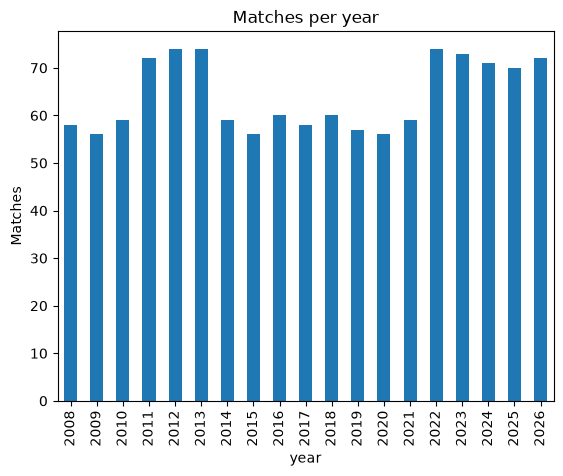

In [8]:
matches_per_year = df.groupby("year")["match_id"].nunique()
matches_per_year.plot(kind="bar", title="Matches per year")
plt.ylabel("Matches")
plt.show()

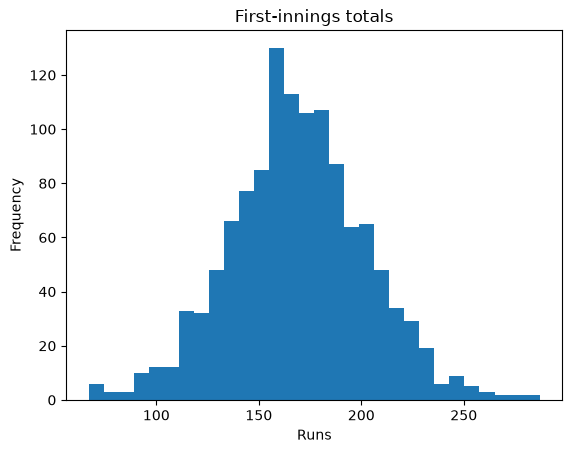

Average first-innings total: 169.0
Chasing team won: 54.7 % of matches


In [9]:
first_total = df[df["innings"] == 1].groupby("match_id")["runs_so_far"].max()
first_total.plot(kind="hist", bins=30, title="First-innings totals")
plt.xlabel("Runs")
plt.show()

chase_won = df[df["innings"] == 2].groupby("match_id")["batting_team_won"].first()
print("Average first-innings total:", round(first_total.mean(), 1))
print("Chasing team won:", round(chase_won.mean() * 100, 1), "% of matches")

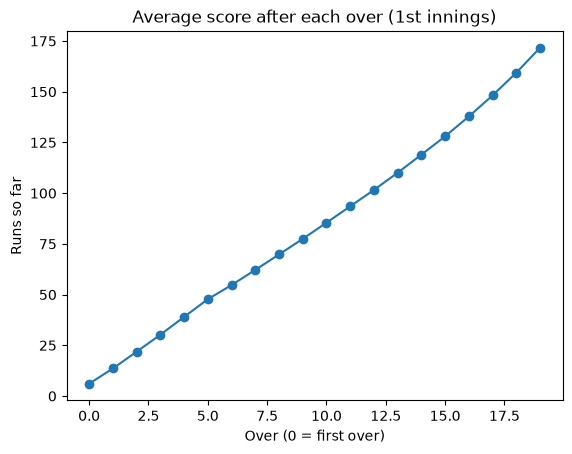

In [10]:
inn1 = df[df["innings"] == 1]
score_after_over = inn1.groupby(["match_id", "over"])["runs_so_far"].last().groupby("over").mean()
score_after_over.plot(marker="o", title="Average score after each over (1st innings)")
plt.xlabel("Over (0 = first over)")
plt.ylabel("Runs so far")
plt.show()

In [11]:
chase_overs = df[df["innings"] == 2].groupby("match_id")["target_overs"].first()
reduced_ids = chase_overs[chase_overs != 20].index
print("Rain-shortened matches removed:", len(reduced_ids))

df = df[~df["match_id"].isin(reduced_ids)].copy()
print("Matches left:", df["match_id"].nunique(), "| rows:", len(df))

Rain-shortened matches removed: 33
Matches left: 1185 | rows: 285001


In [12]:
first_total = df[df["innings"] == 1].groupby("match_id")["runs_so_far"].max()

chase = df[df["innings"] == 2].copy()
chase["first_total"] = chase["match_id"].map(first_total)
print("target_runs == first_total + 1:", round((chase["target_runs"] == chase["first_total"] + 1).mean() * 100, 1), "%")
print("target_runs == first_total    :", round((chase["target_runs"] == chase["first_total"]).mean() * 100, 1), "%")

target_runs == first_total + 1: 100.0 %
target_runs == first_total    : 0.0 %


In [13]:
df["balls_left"] = (120 - df["legal_balls_bowled"]).clip(lower=0)
df["wickets_in_hand"] = 10 - df["wickets_so_far"]
df["crr"] = df["runs_so_far"] / (df["legal_balls_bowled"].clip(lower=1) / 6)

In [14]:
df["target"] = df["match_id"].map(first_total) + 1

is_chase = df["innings"] == 2
df["runs_left"] = np.where(is_chase, df["target"] - df["runs_so_far"], 0)

rrr = df["runs_left"].clip(lower=0) / (df["balls_left"].clip(lower=1) / 6)
df["rrr"] = np.where(is_chase, rrr.clip(upper=36), 0)
df["rr_diff"] = np.where(is_chase, df["crr"] - df["rrr"], 0)

In [15]:
FEATURES = ["innings", "runs_so_far", "wickets_in_hand", "balls_left", "crr", "runs_left", "rrr", "rr_diff"]
LABEL = "batting_team_won"

print("Missing values:", int(df[FEATURES].isna().sum().sum()))
print("Infinite values:", int(np.isinf(df[FEATURES]).sum().sum()))
df[FEATURES + [LABEL]].describe().T[["mean", "min", "max"]]

Missing values: 0
Infinite values: 0


,mean,min,max
innings,1.483812,1.0,2.000000
runs_so_far,78.539317,0.0,287.000000
wickets_in_hand,7.526696,0.0,10.000000
balls_left,61.142775,0.0,120.000000
crr,7.782902,0.0,66.000000
runs_left,46.383792,-5.0,287.000000
rrr,4.959182,0.0,36.000000
rr_diff,-1.156201,-31.5,50.369748
batting_team_won,0.490251,0.0,1.000000


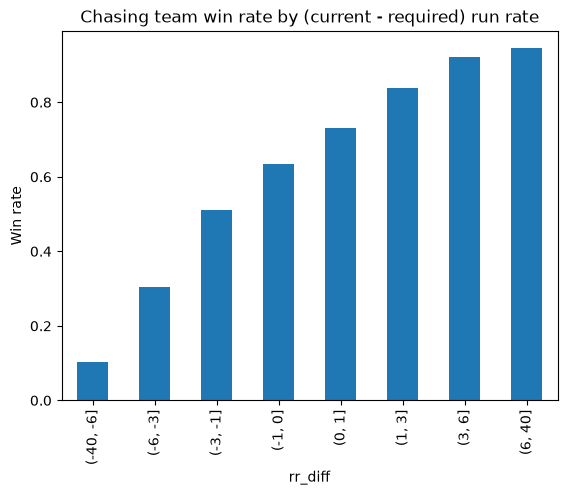

In [16]:
chasing = df[df["innings"] == 2]
bins = [-40, -6, -3, -1, 0, 1, 3, 6, 40]
win_rate_by_diff = chasing.groupby(pd.cut(chasing["rr_diff"], bins), observed=True)["batting_team_won"].mean()
win_rate_by_diff.plot(kind="bar", title="Chasing team win rate by (current - required) run rate")
plt.ylabel("Win rate")
plt.show()

In [17]:
match_order = (df.groupby("match_id")["date"].first().reset_index()
                 .sort_values(["date", "match_id"]))
ids = match_order["match_id"].tolist()
n = len(ids)
n_train, n_val = int(0.70 * n), int(0.15 * n)

train_ids = set(ids[:n_train])
val_ids   = set(ids[n_train:n_train + n_val])
test_ids  = set(ids[n_train + n_val:])

train = df[df["match_id"].isin(train_ids)]
val   = df[df["match_id"].isin(val_ids)]
test  = df[df["match_id"].isin(test_ids)]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:<5} matches={part['match_id'].nunique():>4}  balls={len(part):>7,}  "
          f"{part['date'].min().date()} -> {part['date'].max().date()}")

X_train, y_train = train[FEATURES], train[LABEL]
X_val,   y_val   = val[FEATURES],   val[LABEL]
X_test,  y_test  = test[FEATURES],  test[LABEL]

train matches= 829  balls=198,965  2008-04-18 -> 2021-10-10
val   matches= 177  balls= 43,053  2021-10-11 -> 2024-04-14
test  matches= 179  balls= 42,983  2024-04-15 -> 2026-05-31


In [18]:
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss, roc_auc_score

def evaluate(y_true, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {"accuracy": accuracy_score(y_true, p >= 0.5),
            "log_loss": log_loss(y_true, p),
            "brier": brier_score_loss(y_true, p),
            "auc": roc_auc_score(y_true, p)}

# Baseline 1: always predict the training win rate
p_const = np.full(len(y_val), y_train.mean())

# Baseline 2: run-rate rule, with win rates learned from TRAIN only
chase_tr = train["innings"] == 2
ahead_tr = train["rr_diff"] >= 0
rate_ahead  = train.loc[chase_tr & ahead_tr,  LABEL].mean()
rate_behind = train.loc[chase_tr & ~ahead_tr, LABEL].mean()

def rule_baseline(frame):
    p = np.full(len(frame), 0.5)
    chase = (frame["innings"] == 2).values
    ahead = (frame["rr_diff"] >= 0).values
    p[chase & ahead] = rate_ahead
    p[chase & ~ahead] = rate_behind
    return p

baseline_val = pd.DataFrame({"constant": evaluate(y_val, p_const),
                             "run-rate rule": evaluate(y_val, rule_baseline(val))}).T
baseline_val.round(4)

,accuracy,log_loss,brier,auc
constant,0.5070,0.6931,0.250,0.5000
run-rate rule,0.6096,0.6476,0.228,0.6531


In [19]:
from sklearn.tree import DecisionTreeClassifier

configs = {"no limits": {}, "limited": {"max_depth": 6, "min_samples_leaf": 200}}
for name, params in configs.items():
    tree = DecisionTreeClassifier(random_state=0, **params).fit(X_train, y_train)
    tr = evaluate(y_train, tree.predict_proba(X_train)[:, 1])
    va = evaluate(y_val,   tree.predict_proba(X_val)[:, 1])
    print(f"{name:<10} | train log-loss {tr['log_loss']:.3f}  val log-loss {va['log_loss']:.3f}"
          f" | train acc {tr['accuracy']:.3f}  val acc {va['accuracy']:.3f}")

no limits  | train log-loss 0.253  val log-loss 3.248 | train acc 0.851  val acc 0.633
limited    | train log-loss 0.549  val log-loss 0.569 | train acc 0.679  val acc 0.670


In [20]:
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

knn_sample = train.sample(min(40000, len(train)), random_state=0)   # KNN is slow, so it trains on a sample

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Naive Bayes":         make_pipeline(StandardScaler(), GaussianNB()),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=0),
    "KNN (k=100)":         make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=100)),
    "Random Forest":       RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=100,
                                                  max_samples=0.5, n_jobs=-1, random_state=0),
    "Gradient Boosting":   HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_depth=6,
                                                          min_samples_leaf=100, early_stopping=False,
                                                          random_state=0),
}

fitted, val_rows = {}, {}
for name, model in models.items():
    start = time.time()
    if name.startswith("KNN"):
        model.fit(knn_sample[FEATURES], knn_sample[LABEL])
    else:
        model.fit(X_train, y_train)
    p_val = model.predict_proba(X_val)[:, 1]
    val_rows[name] = {**evaluate(y_val, p_val), "seconds": round(time.time() - start)}
    fitted[name] = model
    print(f"done: {name} ({time.time() - start:.0f}s)")

val_table = pd.concat([baseline_val, pd.DataFrame(val_rows).T]).sort_values("log_loss")
val_table.round(4)

done: Logistic Regression (0s)
done: Naive Bayes (0s)
done: Decision Tree (0s)
done: KNN (k=100) (2s)
done: Random Forest (1s)
done: Gradient Boosting (1s)


,accuracy,log_loss,brier,auc,seconds
Gradient Boosting,0.7014,0.5420,0.1855,0.7896,1.0
Logistic Regression,0.7014,0.5462,0.1868,0.7871,0.0
Random Forest,0.6976,0.5491,0.1878,0.7847,1.0
KNN (k=100),0.6901,0.5608,0.1903,0.7766,2.0
Decision Tree,0.6697,0.5688,0.1955,0.7602,0.0
run-rate rule,0.6096,0.6476,0.2280,0.6531,NaN
constant,0.5070,0.6931,0.2500,0.5000,NaN
Naive Bayes,0.6390,0.7274,0.2432,0.7180,0.0


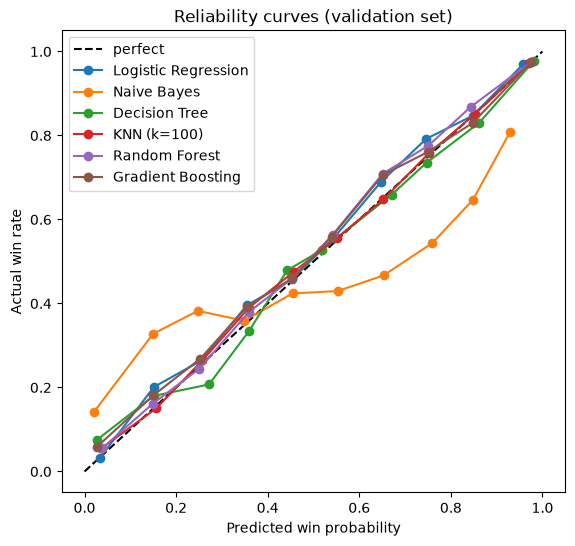

In [21]:
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], "k--", label="perfect")
for name, model in fitted.items():
    p = model.predict_proba(X_val)[:, 1]
    frac_won, mean_pred = calibration_curve(y_val, p, n_bins=10)
    ax.plot(mean_pred, frac_won, marker="o", label=name)
ax.set_xlabel("Predicted win probability")
ax.set_ylabel("Actual win rate")
ax.set_title("Reliability curves (validation set)")
ax.legend()
plt.show()

In [22]:
candidates = val_table.drop(index=["constant", "run-rate rule"])
best_name = candidates["log_loss"].idxmin()
best_model = fitted[best_name]
print("Best model on validation:", best_name)

p_test = best_model.predict_proba(X_test)[:, 1]
test_table = pd.DataFrame({
    best_name:       evaluate(y_test, p_test),
    "constant":      evaluate(y_test, np.full(len(y_test), y_train.mean())),
    "run-rate rule": evaluate(y_test, rule_baseline(test)),
}).T
test_table.round(4)

Best model on validation: Gradient Boosting


,accuracy,log_loss,brier,auc
Gradient Boosting,0.7234,0.5692,0.1882,0.7973
constant,0.5124,0.6929,0.2499,0.5000
run-rate rule,0.5888,0.6255,0.2184,0.6803


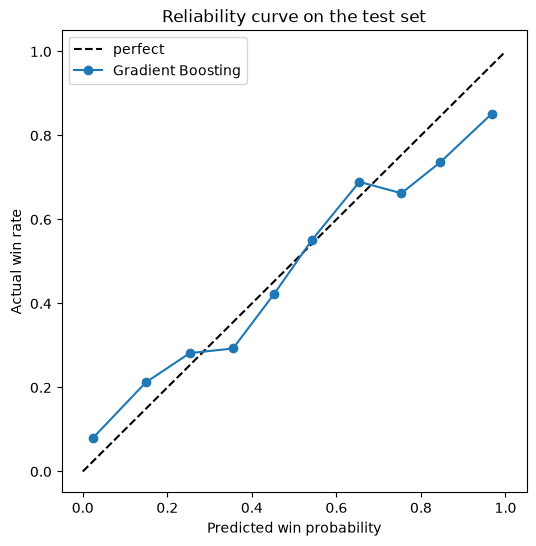

In [23]:
frac_won, mean_pred = calibration_curve(y_test, p_test, n_bins=10)
plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.plot(mean_pred, frac_won, marker="o", label=best_name)
plt.xlabel("Predicted win probability")
plt.ylabel("Actual win rate")
plt.title("Reliability curve on the test set")
plt.legend()
plt.show()

In [24]:
rows = {}
for inn in [1, 2]:
    mask = (test["innings"] == inn).values
    rows[f"innings {inn}"] = evaluate(y_test[mask], p_test[mask])
pd.DataFrame(rows).T.round(4)

,accuracy,log_loss,brier,auc
innings 1,0.6383,0.7028,0.2395,0.7097
innings 2,0.8161,0.4239,0.1324,0.9154
